In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import statsmodels.api as sm

In [7]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [8]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [9]:
df.shape


(2443651, 9)

In [10]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [11]:
# Part 1: Analyzing Best-Seller Trends Across Product Categories
# Objective: Understand the relationship between product categories and their best-seller status.

# Crosstab Analysis:

# Create a crosstab between the product category and the isBestSeller status.
bestseller_crosstab = pd.crosstab(
    df["category"],
    df["isBestSeller"]
)

bestseller_crosstab

# Are there categories where being a best-seller is more prevalent?

# Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

# Statistical Tests:

# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
# Compute Cramér's V to understand the strength of association between best-seller status and category.
# Visualizations:

# Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [12]:

# Are there categories where being a best-seller is more prevalent?

# Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.
bestseller_proportions = pd.crosstab(
    df["category"],
    df["isBestSeller"],
    normalize="index"
)

bestseller_proportions.head()

bestseller_ranking = (
    bestseller_proportions[True]
    .sort_values(ascending=False)
)

bestseller_ranking.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Mirrors                           0.028000
Wind Instruments                  0.028000
Name: True, dtype: float64

In [16]:
# Statistical Tests:

# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
from scipy.stats import chi2_contingency
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    bestseller_crosstab
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", degrees_of_freedom)

if p_value < 0.05:
    print("There is a statistically significant association between category and best-seller status.")
else:
    print("There is not enough evidence of an association between category and best-seller status.")


# Compute Cramér's V to understand the strength of association between best-seller status and category.

cramers_v = association(
    bestseller_crosstab,
    method="cramer"
)

print("Cramér's V:", cramers_v)


Chi-square statistic: 36540.20270061387
P-value: 0.0
Degrees of freedom: 295
There is a statistically significant association between category and best-seller status.
Cramér's V: 0.1222829439760564


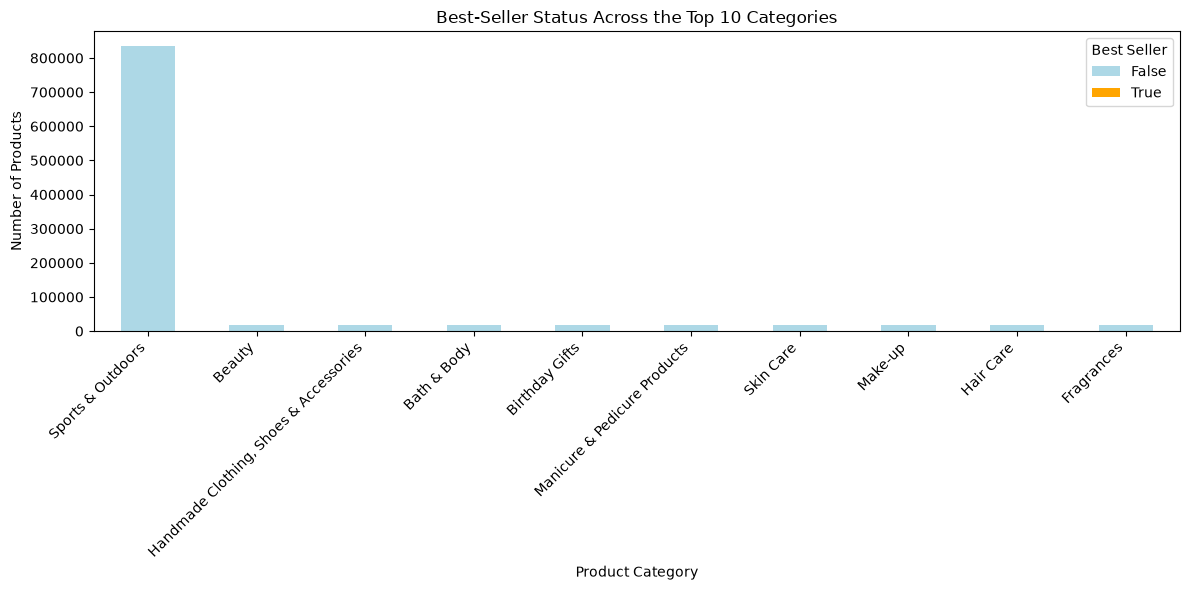

In [20]:
# Visualizations:

# Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

top_10_categories = df["category"].value_counts().head(10).index
top_10_crosstab = bestseller_crosstab.loc[top_10_categories]

top_10_crosstab.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["lightblue", "orange"]
)

plt.title("Best-Seller Status Across the Top 10 Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Best Seller")
plt.tight_layout()
plt.show()

In [23]:
# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
# Objective: Investigate how different product categories influence product prices.

# Preliminary Step: Remove outliers in product prices.

# For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
].copy()

print("Original rows:", df.shape[0])
print("Rows after removing outliers:", df_no_outliers.shape[0])
print("Rows removed:", df.shape[0] - df_no_outliers.shape[0])
# Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

# Violin Plots:

# Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
# Which product category tends to have the highest median price? Don't filter here by top categories.
# Bar Charts:

# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
# Which product category commands the highest average price? Don't filter here by top categories.
# Box Plots:

# Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

Q1: 9.99
Q3: 45.99
IQR: 36.0
Lower boundary: -44.01
Upper boundary: 99.99000000000001
Original rows: 2443651
Rows after removing outliers: 2115963
Rows removed: 327688


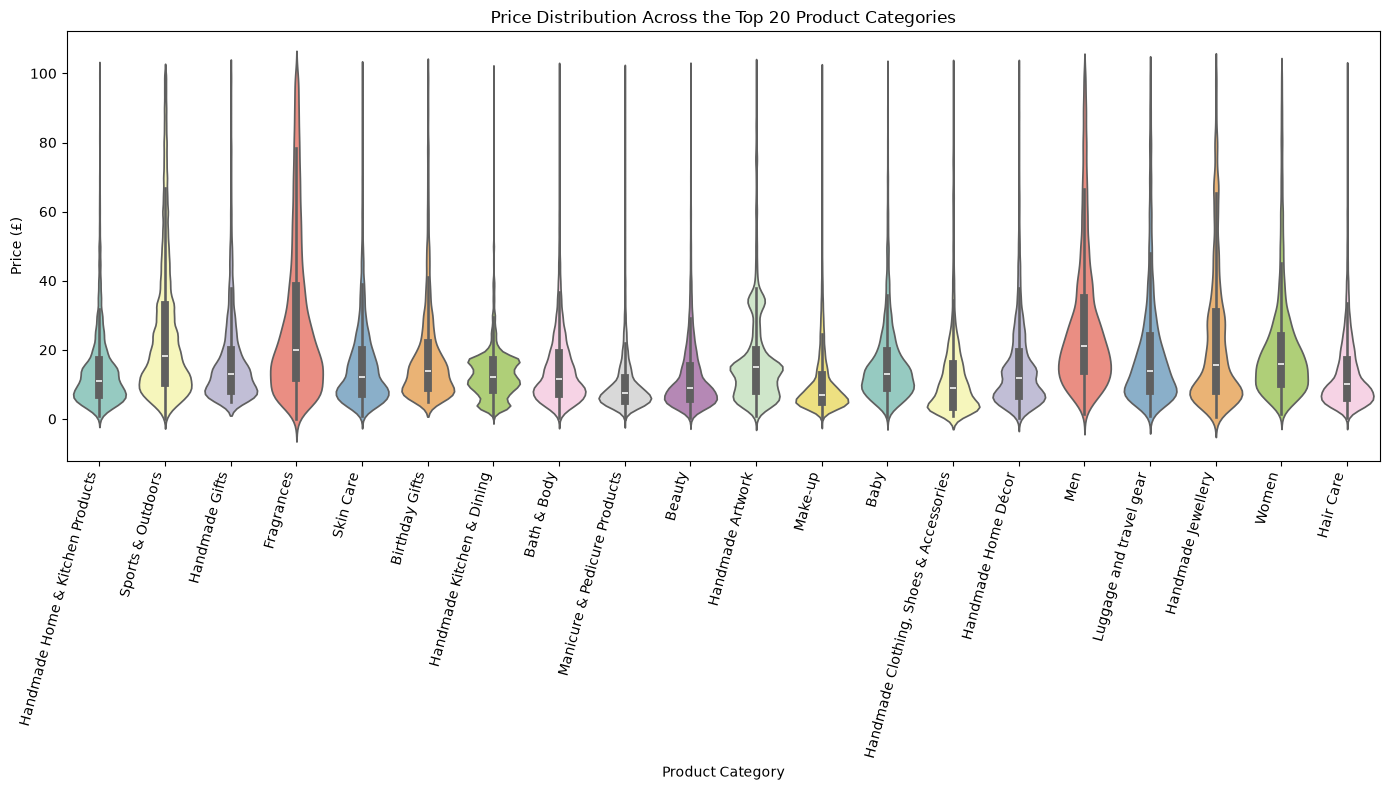

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [25]:
# Violin Plots:

# Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
# Which product category tends to have the highest median price? Don't filter here by top categories.

top_20_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

df_top_20 = df_no_outliers[
    df_no_outliers["category"].isin(top_20_categories)
]

plt.figure(figsize=(14, 8))

sns.violinplot(
    data=df_top_20,
    x="category",
    y="price",
    hue="category",
    palette="Set3",
    legend=False
)

plt.title("Price Distribution Across the Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price (£)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

median_price_by_category = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_category.head(10)

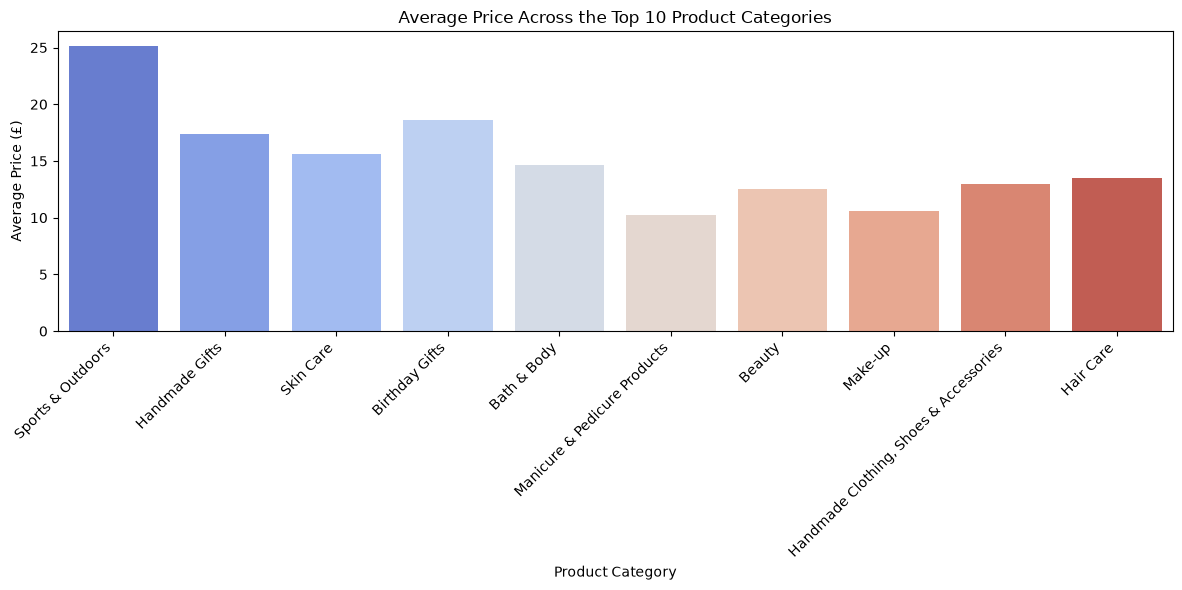

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

In [28]:
# Bar Charts:

# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

df_top_10 = df_no_outliers[
    df_no_outliers["category"].isin(top_10_categories)
]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_top_10,
    x="category",
    y="price",
    hue="category",
    palette="coolwarm",
    legend=False,
    errorbar=None
)

plt.title("Average Price Across the Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Which product category commands the highest average price? Don't filter here by top categories.

average_price_by_category = (
    df_no_outliers
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

average_price_by_category.head(10)


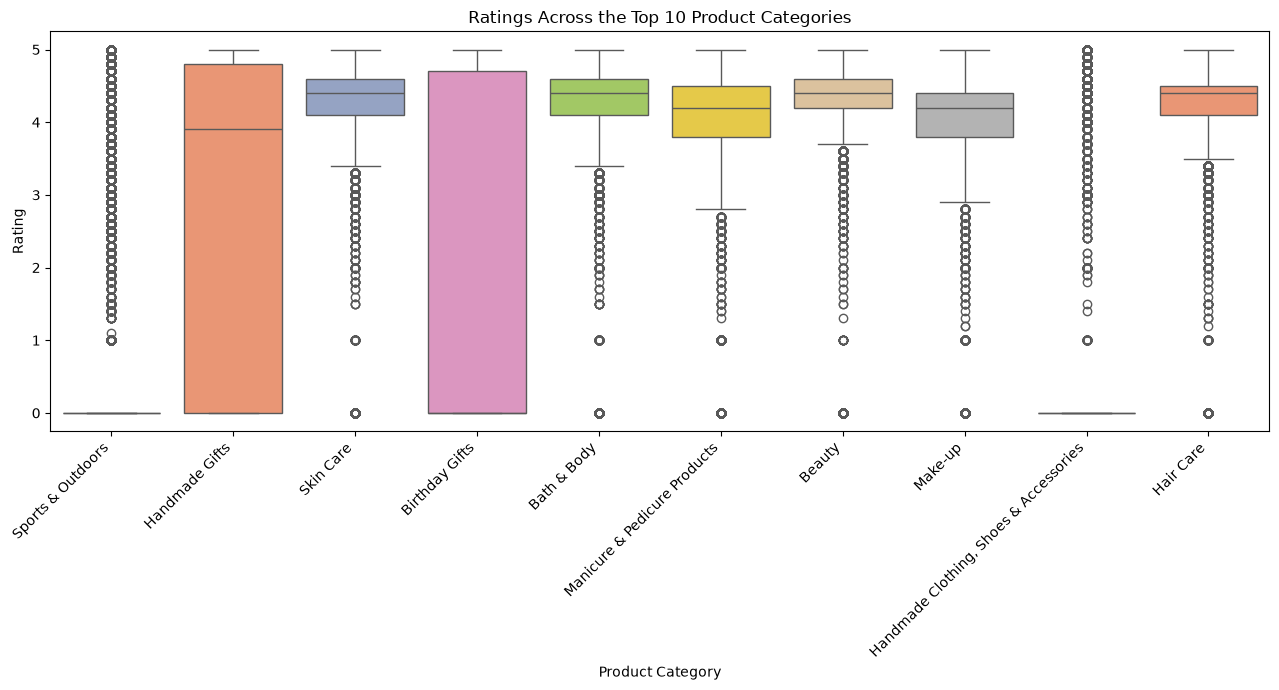

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

In [29]:
# Box Plots:

# Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

df_top_10 = df_no_outliers[
    df_no_outliers["category"].isin(top_10_categories)
]

plt.figure(figsize=(13, 7))

sns.boxplot(
    data=df_top_10,
    x="category",
    y="stars",
    hue="category",
    palette="Set2",
    legend=False
)

plt.title("Ratings Across the Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.
median_rating_by_category = (
    df_no_outliers
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_rating_by_category.head(10)

Pearson correlation: -0.07767299878181323


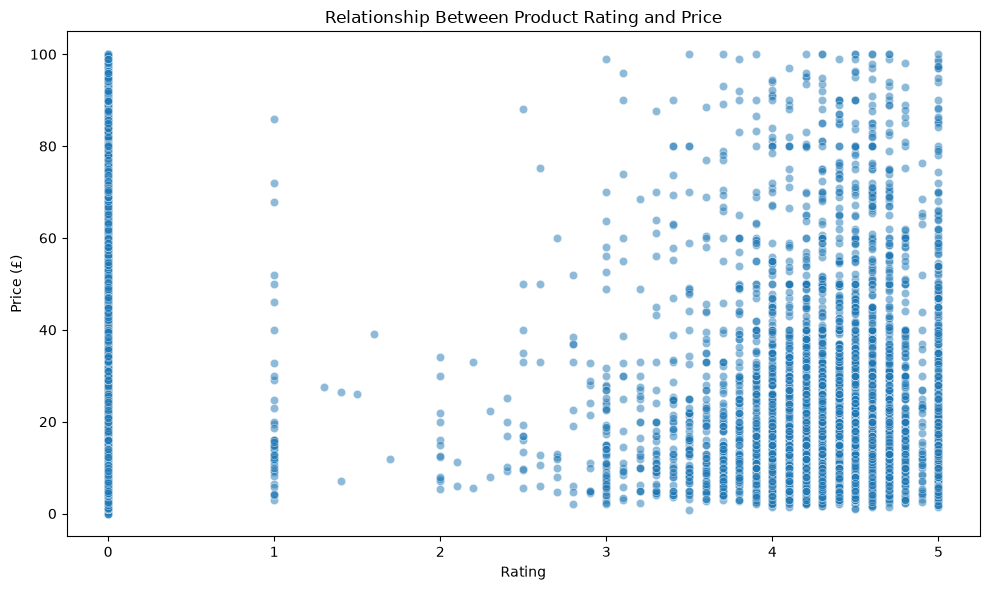

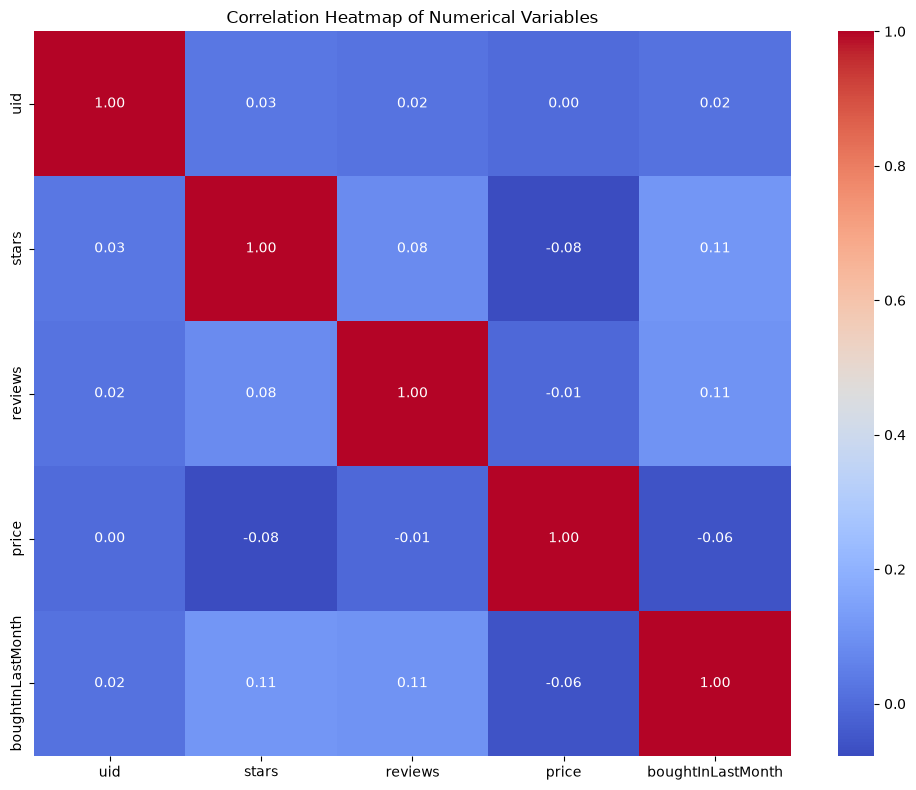

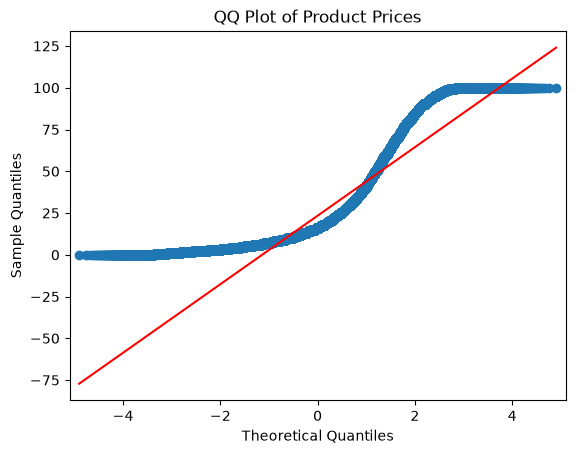

In [36]:
# Part 3: Investigating the Interplay Between Product Prices and Ratings
# Objective: Analyze how product ratings (stars) correlate with product prices.

# Correlation Coefficients:

# Calculate the correlation coefficient between price and stars.

price_rating_correlation = df_no_outliers["price"].corr(
    df_no_outliers["stars"]
)

print("Pearson correlation:", price_rating_correlation)
# Is there a significant correlation between product price and its rating?
# Visualizations:

# Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

plot_sample = df_no_outliers.sample(
    n=min(10000, len(df_no_outliers)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_sample,
    x="stars",
    y="price",
    alpha=0.5
)

plt.title("Relationship Between Product Rating and Price")
plt.xlabel("Rating")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()
# Use a correlation heatmap to visualize correlations between all numerical variables.

numerical_columns = df_no_outliers.select_dtypes(include="number")

correlation_matrix = numerical_columns.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

# Examine if product prices typically follow a normal distribution using a QQ plot.
sm.qqplot(
    df_no_outliers["price"].dropna(),
    line="s"
)

plt.title("QQ Plot of Product Prices")
plt.show()

Final business report
Part 1: Best-seller trends
The category with the highest proportion of best-selling products was Grocery, with a best-seller rate of 0.058135%. The Chi-square test produced a p-value of 0.0, indicating that product category and best-seller status are not statistically associated. However, Cramér’s V was  0.1222829439760564, showing that the relationship was weak.

Part 2: Price and rating differences
After removing price outliers using the IQR method, Desktop PCs had the highest median price, while Motherboards had the highest average price. The category with the highest median customer rating was Computer Memory. Categories showed different levels of price spread, suggesting that product category is relevant when examining Amazon pricing.

Part 3: Price and rating relationship
The correlation between product price and rating was -0.07767299878181323. This represents a weak negative relationship. The scatter plot did not show a clear pattern. The QQ plot showed that prices were not normally distributed.